In [1]:
import IJulia
import Base64

# The julia kernel has built in support for Revise.jl, so this is the 
# recommended approach for long-running sessions:
# https://github.com/JuliaLang/IJulia.jl/blob/9b10fa9b879574bbf720f5285029e07758e50a5e/src/kernel.jl#L46-L51

# Users should enable revise within .julia/config/startup_ijulia.jl:
# https://timholy.github.io/Revise.jl/stable/config/#Using-Revise-automatically-within-Jupyter/IJulia-1

# clear console history
IJulia.clear_history()

fig_width = 10
fig_height = 5
fig_format = :retina
fig_dpi = 96

# no retina format type, use svg for high quality type/marks
if fig_format == :retina
  fig_format = :svg
elseif fig_format == :pdf
  fig_dpi = 96
  # Enable PDF support for IJulia
  IJulia.register_mime(MIME("application/pdf"))
end

# convert inches to pixels
fig_width = fig_width * fig_dpi
fig_height = fig_height * fig_dpi

# Intialize Plots w/ default fig width/height
try
  import Plots

  # Plots.jl doesn't support PDF output for versions < 1.28.1
  # so use png (if the DPI remains the default of 300 then set to 96)
  if (Plots._current_plots_version < v"1.28.1") & (fig_format == :pdf)
    Plots.gr(size=(fig_width, fig_height), fmt = :png, dpi = fig_dpi)
  else
    Plots.gr(size=(fig_width, fig_height), fmt = fig_format, dpi = fig_dpi)
  end
catch e
  # @warn "Plots init" exception=(e, catch_backtrace())
end

# Initialize CairoMakie with default fig width/height
try
  import CairoMakie

  # CairoMakie's display() in PDF format opens an interactive window
  # instead of saving to the ipynb file, so we don't do that.
  # https://github.com/quarto-dev/quarto-cli/issues/7548
  if fig_format == :pdf
    CairoMakie.activate!(type = "png")
  else
    CairoMakie.activate!(type = string(fig_format))
  end
  CairoMakie.update_theme!(resolution=(fig_width, fig_height))
catch e
    # @warn "CairoMakie init" exception=(e, catch_backtrace())
end
  
# Set run_path if specified
try
  run_path = "L1VzZXJzL211bGxpbnNqL0Ryb3Bib3gvVGVhY2hpbmcvRUNPTjQ1MzgvbGVjdHVyZXM="
  if !isempty(run_path)
    run_path = String(Base64.base64decode(run_path))
    cd(run_path)
  end
catch e
  @warn "Run path init:" exception=(e, catch_backtrace())
end


# emulate old Pkg.installed beahvior, see
# https://discourse.julialang.org/t/how-to-use-pkg-dependencies-instead-of-pkg-installed/36416/9
import Pkg
function isinstalled(pkg::String)
  any(x -> x.name == pkg && x.is_direct_dep, values(Pkg.dependencies()))
end

# ojs_define
if isinstalled("JSON") && isinstalled("DataFrames")
  import JSON, DataFrames
  global function ojs_define(; kwargs...)
    convert(x) = x
    convert(x::DataFrames.AbstractDataFrame) = Tables.rows(x)
    content = Dict("contents" => [Dict("name" => k, "value" => convert(v)) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
elseif isinstalled("JSON")
  import JSON
  global function ojs_define(; kwargs...)
    content = Dict("contents" => [Dict("name" => k, "value" => v) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
else
  global function ojs_define(; kwargs...)
    @warn "JSON package not available. Please install the JSON.jl package to use ojs_define."
  end
end


# don't return kernel dependencies (b/c Revise should take care of dependencies)
nothing


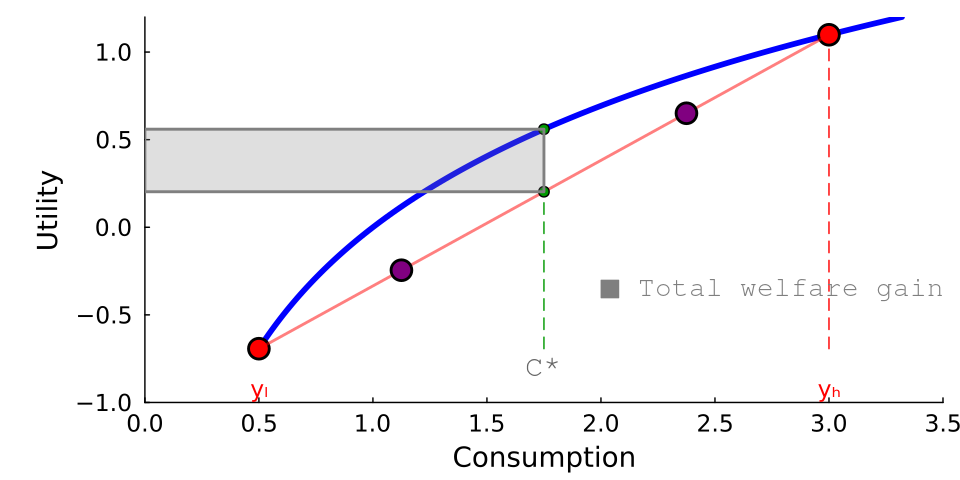

GKS: could not find font bold.ttf


In [2]:
#| echo: false

using Plots

y_L, y_H = 0.5, 3.0
y_range = range(0.5, 3.5, length=200)
y_min = log(y_L)
green = RGB(0, 0.6, 0)

# Key quantities in Example 1 with log utility; p_low is π on the slides
function ex1(p_low)
    C_star = 0.5*y_H + 0.5*y_L                    # planner's consumption
    W_0 = 0.5*log(y_L) + 0.5*log(y_H)             # laissez-faire welfare
    U_L = p_low*log(y_L) + (1-p_low)*log(y_H)     # V_L
    U_H = p_low*log(y_H) + (1-p_low)*log(y_L)     # V_H
    E_L = p_low*y_L + (1-p_low)*y_H               # expected income, type L
    E_H = p_low*y_H + (1-p_low)*y_L               # expected income, type H
    c_L, c_H = exp(U_L), exp(U_H)                 # certainty equivalents
    (; C_star, W_0, U_L, U_H, E_L, E_H, c_L, c_H,
       U_star = log(C_star), C_bar = 0.5*c_L + 0.5*c_H)
end

# Utility curve, income realizations and the chord between them
function base_plot()
    plot(y_range, log.(y_range), linewidth=4, color=:blue,
         xlabel="Consumption", ylabel="Utility", legend=false,
         size=(1000, 500), grid=false, thickness_scaling=1.5,
         guidefontsize=13, tickfontsize=11, xlims=(0., 3.5), ylims=(-1., 1.2))
    scatter!([y_L, y_H], [log(y_L), log(y_H)], markersize=8, color=:red, markerstrokewidth=2)
    plot!([y_L, y_H], [log(y_L), log(y_H)], color=:red, linewidth=2, alpha=0.5)
    annotate!(y_L, -0.92, text("yₗ", :red, :center, 11))
    annotate!(y_H, -0.92, text("yₕ", :red, :center, 11))
end

# Shaded band between utility levels lo and hi, with a label
function band!(v, lo, hi, color, label, label_y)
    plot!([0, v.C_star, v.C_star, 0, 0], [lo, lo, hi, hi, lo], fillrange=lo,
          fillalpha=0.25, fillcolor=color, linecolor=color, linewidth=2)
    annotate!(2.0, label_y, text("■ " * label, color, :left, 10, :bold))
end

# Final picture: the decomposition into insurance and redistribution
function decomposition_plot(v)
    base_plot()
    plot!([0, v.C_star], [v.W_0, v.W_0], linestyle=:dash, color=:red, linewidth=2.5)
    plot!([0, v.C_bar], [log(v.C_bar), log(v.C_bar)], linestyle=:dash, color=:orange, linewidth=2.5)
    plot!([0, v.C_star], [v.U_star, v.U_star], linestyle=:dash, color=green, linewidth=2.5)
    plot!([v.C_star, v.C_star], [y_min, v.U_star], linestyle=:dash, color=green)
    scatter!([v.E_L, v.E_H], [v.U_L, v.U_H], markersize=8, color=:purple, markerstrokewidth=2)
    plot!([v.C_bar, v.C_bar], [y_min, log(v.C_bar)], color=:orange, linewidth=2, alpha=0.5, linestyle=:dot)
    annotate!(v.c_L, -0.8, text("c̄ₗ", :purple, :center, 11))
    annotate!(v.c_H, -0.8, text("c̄ₕ", :purple, :center, 11))
    annotate!(v.C_bar, -0.8, text("C̄", :orange, :center, 11, :bold))
    annotate!(v.C_star, -0.8, text("C*", green, :center, 11, :bold))
    band!(v, v.W_0, log(v.C_bar), :orange, "Redistribution gain", -0.45)
    band!(v, log(v.C_bar), v.U_star, green, "Insurance gain", -0.25)
end

v = ex1(0.75)
base_plot()
plot!([y_H, y_H], [y_min, log(y_H)], linestyle=:dash, color=:red)
scatter!([v.E_L, v.E_H], [v.U_L, v.U_H], markersize=8, color=:purple, markerstrokewidth=2)
scatter!([v.C_star, v.C_star], [v.W_0, v.U_star], color=green)
plot!([v.C_star, v.C_star], [y_min, v.U_star], linestyle=:dash, color=green)
annotate!(v.C_star, -0.8, text("C*", green, :center, 11, :bold))
band!(v, v.W_0, v.U_star, :gray, "Total welfare gain", -0.35)

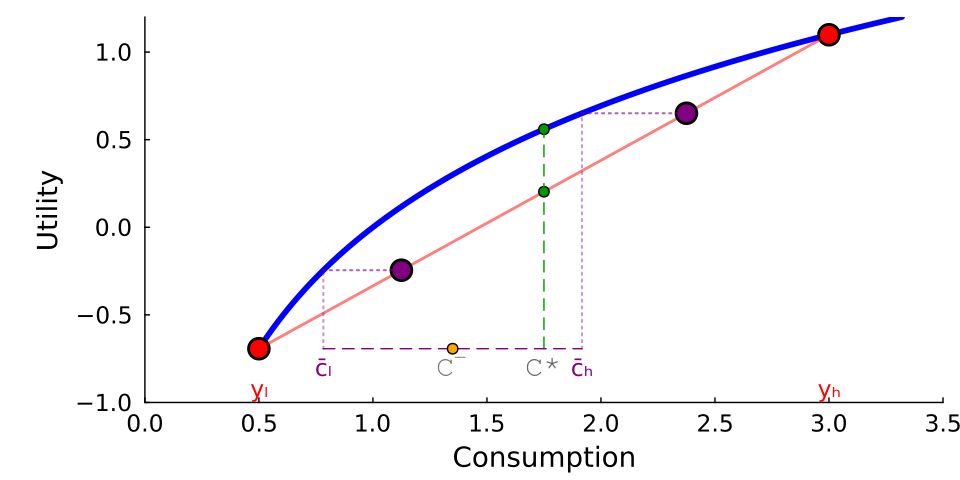

In [3]:
#| echo: false
base_plot()
scatter!([v.C_star, v.C_star], [v.W_0, v.U_star], color=green)
scatter!([v.E_L, v.E_H], [v.U_L, v.U_H], markersize=8, color=:purple, markerstrokewidth=2)
for (c, E, U) in ((v.c_L, v.E_L, v.U_L), (v.c_H, v.E_H, v.U_H))
    plot!([c, E], [U, U], color=:purple, linewidth=1.5, alpha=0.6, linestyle=:dot)
    plot!([c, c], [y_min, U], color=:purple, linewidth=1.5, alpha=0.4, linestyle=:dot)
end
plot!([v.C_star, v.C_star], [y_min, v.U_star], linestyle=:dash, color=green)
plot!([v.c_L, v.c_H], [y_min, y_min], color=:purple, linestyle=:dash)
scatter!([v.C_bar], [y_min], color=:orange)
annotate!(v.c_L, -0.8, text("c̄ₗ", :purple, :center, 11))
annotate!(v.c_H, -0.8, text("c̄ₕ", :purple, :center, 11))
annotate!(v.C_bar, -0.8, text("C̄", :orange, :center, 11, :bold))
annotate!(v.C_star, -0.8, text("C*", green, :center, 11, :bold))

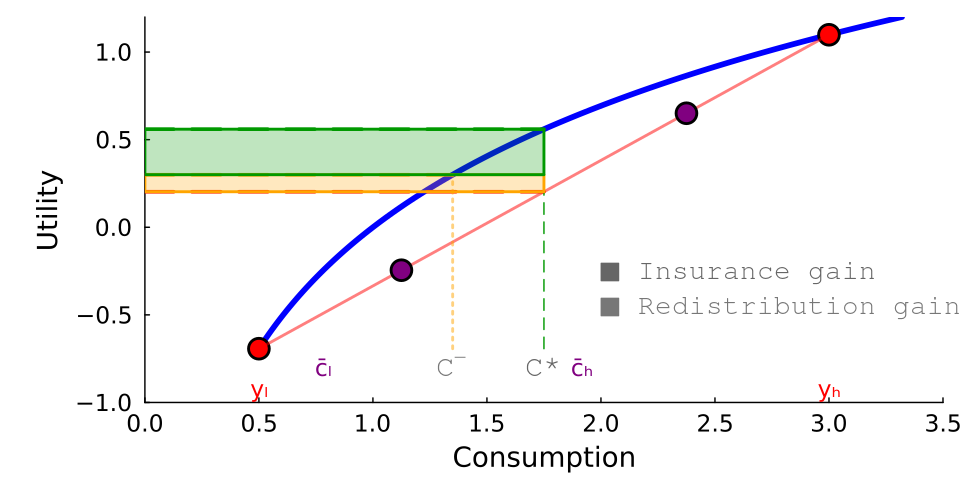

In [4]:
#| echo: false
decomposition_plot(v)

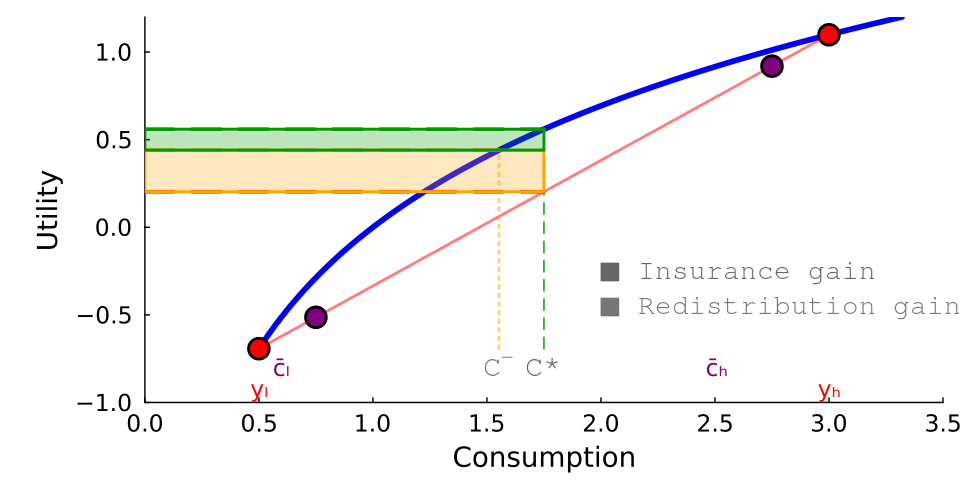

In [5]:
#| echo: false
decomposition_plot(ex1(0.9))